In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import numpy as np
import os
import re
from pysuto.util import get_path

p = '/mnt/nfs_fineprint/tmp/PYSUT/pySUTO/data/input/raw/Soulier_2018/Copper_HS92_Table_Merged.csv'

In [8]:
d = pd.read_csv(p)
d

,HS92 Code,Short description,Est. Content,Model Variable,Source Code,Source Content,Source Variable,Sector,Phase
0,260300,Copper ores and concentrates,30.00%,Concentrate,"[1], [2]","[3], [4], [5]",Est.,Concentrate,Mining
1,262030,Ash or residues containing mainly copper,10.00%,Scrap: Ashes,[1],[1],Est.,Scrap,WT
2,282550,Copper oxides and hydroxides,69.00%,Scrap: Powders,[1],[1],Est.,NaN,NaN
3,282741,Chloride oxides and chloride hydroxides of copper,60.00%,Powders,[1],[1],Est.,NaN,NaN
4,283325,Copper sulphates,25.00%,Powders,[1],[1],Est.,NaN,NaN
...,...,...,...,...,...,...,...,...,...
309,920510,Brass-wind instruments,85.00%,Consumer products,[1],[1],Est.,NaN,Use
310,930610,"Cartridges for rivet etc tools, humane killers...",95.00%,Diverse,[1],[1],Est.,NaN,Use
311,930621,"Cartridges, shotgun",95.00%,Diverse,[1],[1],Est.,NaN,Use
312,930690,"Munitions of war, ammunition/projectiles and p...",95.00%,Diverse,[1],[1],Est.,NaN,Use


In [23]:
def parse_content(val):
    if pd.isna(val):
        return np.nan
    nums = re.findall(r"\d+\.?\d*", str(val))
    nums = [float(n) for n in nums]
    return np.mean(nums) if nums else np.nan


def plot_phase_content(df):

    df = df.copy()

    # ---- convert concentration ----
    df["Est_Content_float"] = df["Est. Content"].apply(parse_content)

    # remove rows without phase
    df = df.dropna(subset=["Phase"])

    # ---- fixed phase order ----
    phase_order = ["Mining", "Smelting", "Refining", "Semi", "Use", "WT"]

    df = df[df["Phase"].isin(phase_order)]

    # ---- statistics ----
    counts = df.groupby("Phase")["HS92 Code"].count().reindex(phase_order)
    medians = df.groupby("Phase")["Est_Content_float"].median().reindex(phase_order)

    # ---- styling ----
    sns.set_theme(style="white")

    box_color = "#d08c3f"   # copper
    bar_color = "#4a6fa5"   # muted blue
    mean_color = "#8a3f16"
    count_line = "#243447"

    fig, ax1 = plt.subplots(figsize=(10,6))

    # ---- boxplot ----
    sns.boxplot(
        data=df,
        x="Phase",
        y="Est_Content_float",
        order=phase_order,
        width=0.55,
        color=box_color,
        fliersize=2,
        ax=ax1
    )

    ax1.set_ylabel("Copper concentration (%)")
    ax1.set_xlabel("")

    sns.despine(ax=ax1)




    # ---- mean connection line ----
    ax1.plot(
        range(len(phase_order)),
        medians.values,
        color=mean_color,
        marker="o",
        linewidth=2
    )

    # ---- second axis (counts) ----
    ax2 = ax1.twinx()

    ax2.bar(
        range(len(phase_order)),
        counts.values,
        width=0.65,
        color=bar_color,
        alpha=0.25
    )

    ax2.set_ylabel("HS code count")

    # ---- connect bar peaks ----
    ax2.plot(
        range(len(phase_order)),
        counts.values,
        color=count_line,
        marker="o",
        linewidth=2
    )


    # ---- vertical threshold between Semi and Use ----
    threshold_x = 3.415   # between index 3 (Semi) and 4 (Use)

    ax1.axvline(
        x=threshold_x,
        color="#6B8F71",   # elegant muted red
        linestyle="--",
        linewidth=2,
        alpha=0.9
    )

    sns.despine(ax=ax2, left=True)

    plt.tight_layout()
    plt.show()

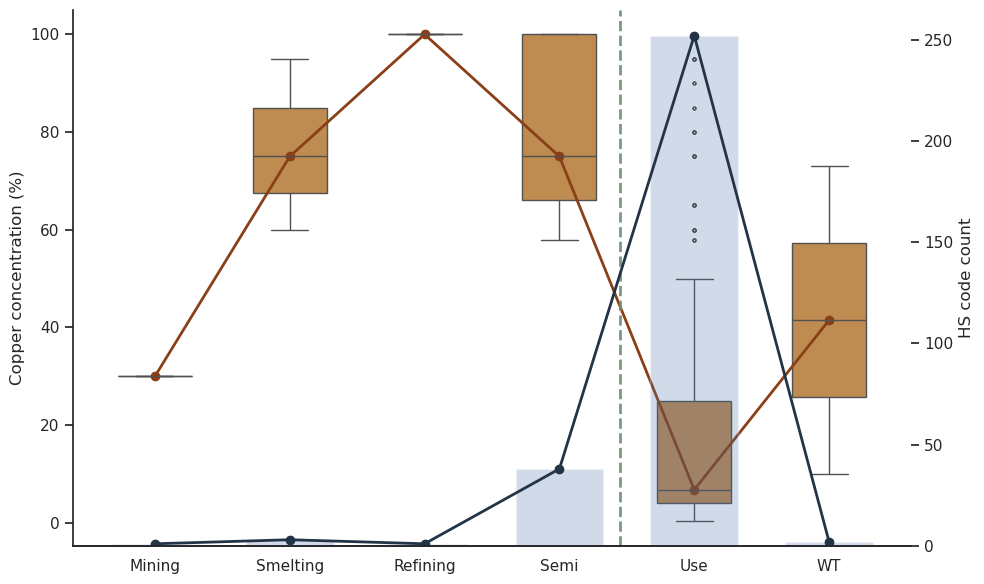

In [22]:
plot_phase_content(d)